# ViajaFácil · Asistente de viajes multiagente
**Flujo en paralelo con LangGraph · RAG sobre el manual · MCP y A2A simulados · aprobación humana con `interrupt()` · Gradio · Notebook resuelto (Colab o local)**

ViajaFácil es una agencia de viajes ficticia. Un cliente escribe:

> *«Quiero ir a Cartagena 4 días en diciembre con mi pareja, presupuesto de 3 millones. ¿Qué me recomiendas? ¿Y si cancelo, qué pasa?»*

Este notebook resuelve la **Actividad ViajaFácil v2** con una arquitectura propia: un **flujo explícito de LangGraph** que consulta tres fuentes **en paralelo** y pide la aprobación del cliente **antes** de reservar. Reutiliza código del curso:

| Lo que verás | Viene de… |
|---|---|
| Contador de llamadas al LLM, datos de vuelos y hoteles | El notebook del reto (`07b_Reto_ViajaFacil_v2`) |
| RAG: manual en Markdown, embeddings e índice en memoria | Laboratorio 6 (`06a`), versión original |
| Servidor de herramientas y agente de otra empresa | Laboratorio 7 (MCP y A2A), aquí **simulados** |
| `interrupt()`, `InMemorySaver` y `Command(resume=...)` | Laboratorio 2 (reembolsos con humano en el bucle) |
| Grafo dibujado con `draw_mermaid_png()` | Laboratorios 0 a 6 |
| Diagrama de secuencia en vivo en Gradio | Laboratorios 6 y 7 |

> ⚠️ Todo es ficticio: vuelos, hoteles, políticas, clima y reservas. No se cobra nada.
> 🔑 Necesitas `GROQ_API_KEY`: en tu PC, en el archivo `.env` de la raíz del repositorio; en Colab, en **Secrets** (icono 🔑).

### 🧭 Recorrido
| Paso | Qué haces |
|---|---|
| 0 | Instalar, conectar con Groq y preparar el **taxímetro** (contador de llamadas) |
| 1 | Bitácora compartida y colores por tipo de mensaje |
| 2 | **Parte A**: el diseño en una tabla y el diagrama de arquitectura |
| 3 | 🗄️ Sistema de reservas como servidor **MCP simulado** |
| 4 | 📚 Manual de políticas y **RAG** |
| 5 | ⛅ Agente Clima de otra empresa por **A2A simulado** |
| 6 | El **grafo**: estado, nodos y aristas (paralelo + humano en el bucle) |
| 7 | Dibujar el grafo con `draw_mermaid_png()` |
| 8 | Pregunta principal: el flujo se **pausa** antes de reservar |
| 9 | El cliente **aprueba** → reserva |
| 10 | Otro caso: el cliente **rechaza** dos veces → nueva propuesta y cancelación |
| 11 | Comprobaciones |
| 12 | **Gradio**: diagrama en vivo, llamadas al LLM y botones Aprobar / Rechazar |
| 13 | Cerrar la interfaz |
| Reto | El Agente Clima como herramienta simple: ¿cuántas llamadas se ahorran? |

## Paso 0 · ▶️ Instalar, conectar y preparar el taxímetro
| Paquete | Para qué |
|---|---|
| `langchain`, `langgraph` | Agentes y el grafo del flujo |
| `langchain-groq` | Groq como LLM |
| `langchain-huggingface`, `sentence-transformers` | Embeddings para el RAG (corren en tu equipo, sin API key) |
| `langchain-text-splitters` | Partir el manual en fragmentos |
| `python-dotenv` | Leer la clave de `.env` en tu PC |

`gradio`, `pandas` y `sentence-transformers` ya vienen en Colab: solo se instalan si faltan.

> **🧩 En palabras simples**
> - **Qué hace esta celda:** instala las librerías que falten.
> - **Piénsalo como:** descargar las apps antes de usarlas.
> - **Qué vas a ver al ejecutarla:** barras de progreso o nada, si ya está todo instalado.

In [1]:
import importlib.util
MODULOS = {'gradio': 'gradio', 'pandas': 'pandas', 'sentence-transformers': 'sentence_transformers'}
faltantes = ' '.join(p for p, m in MODULOS.items() if importlib.util.find_spec(m) is None)
%pip install -q langchain langgraph langchain-groq langchain-huggingface langchain-text-splitters python-dotenv {faltantes}

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


El **taxímetro** es el contador del reto, con una mejora: cuenta las llamadas **por agente**. Cada agente pide su LLM con `nuevo_llm('nombre')`, así se ve dónde se gastan.

> **🧩 En palabras simples**
> - **Qué hace esta celda:** conecta con Groq y crea el contador de llamadas al LLM.
> - **Piénsalo como:** enchufar el cerebro y poner en cero el taxímetro antes del viaje.
> - **Qué vas a ver al ejecutarla:** la palabra `conectado`.

In [2]:
import os, time, json, threading
from dotenv import load_dotenv
from langchain_groq import ChatGroq
from langchain_core.callbacks import BaseCallbackHandler

# 1) La clave de Groq, SIN escribirla en el código
load_dotenv()                                    # en tu PC: carga el archivo .env si existe
GROQ_API_KEY = os.getenv('GROQ_API_KEY')
if not GROQ_API_KEY:
    try:
        from google.colab import userdata        # en Colab: Secrets (icono 🔑)
        GROQ_API_KEY = userdata.get('GROQ_API_KEY')
    except ImportError:
        pass
if not GROQ_API_KEY:
    raise ValueError('Configura GROQ_API_KEY en .env (en tu PC) o en Secrets de Colab.')

MODELO = 'openai/gpt-oss-120b'

# 2) El TAXÍMETRO: cuenta llamadas y tokens, en total y por agente.
#    Las tres ramas del grafo corren a la vez (en hilos), por eso usamos un candado.
class Contador:
    def __init__(self):
        self.candado = threading.Lock()
        self.reiniciar()

    def reiniciar(self):
        self.llamadas, self.tokens, self.por_agente = 0, 0, {}

    def sumar(self, quien, tokens):
        with self.candado:
            self.llamadas += 1
            self.tokens += tokens
            self.por_agente[quien] = self.por_agente.get(quien, 0) + 1

    def resumen(self):
        detalle = ' · '.join(f'{q}: {n}' for q, n in self.por_agente.items())
        return f'{self.llamadas} llamadas al LLM · {self.tokens} tokens' + (f'  ({detalle})' if detalle else '')

CONTADOR = Contador()

class Taximetro(BaseCallbackHandler):     # se "engancha" al LLM y avisa cada vez que responde
    def __init__(self, quien):
        self.quien = quien

    def on_llm_end(self, response, **kwargs):
        try:
            tokens = (response.generations[0][0].message.usage_metadata or {}).get('total_tokens', 0)
        except Exception:
            tokens = 0
        CONTADOR.sumar(self.quien, tokens)

# 3) Cada agente pide su propio LLM, con su nombre para el taxímetro
def nuevo_llm(quien):
    return ChatGroq(model=MODELO, api_key=GROQ_API_KEY, temperature=0, reasoning_effort='low',
                    callbacks=[Taximetro(quien)])

print(nuevo_llm('Prueba').invoke('Responde solo: conectado').content)
CONTADOR.reiniciar()

conectado


## Paso 1 · ▶️ Bitácora compartida
Cada mensaje entre participantes se anota con `registrar(de, para, tipo, accion, detalle)`. El **tipo** decide el color en los diagramas, el mismo que pide la Parte A:

| Tipo | Color | Significa |
|---|---|---|
| `Usuario` / `LLM` | 🟦 azul | Habla el cliente o piensa un LLM del Coordinador |
| `MCP` | 🟩 verde | Herramientas del sistema de reservas |
| `RAG` | 🟧 naranja | Consulta al manual de políticas |
| `A2A` | 🟪 morado | Mensaje al agente de otra empresa |
| `Python` | ⬜ gris | Cálculo determinista (sin LLM) |
| `Humano` | 🟥 rojo | Pausa y decisión del cliente |

> **🧩 En palabras simples**
> - **Qué hace esta celda:** crea el cuaderno de registro y los colores de cada tipo de mensaje.
> - **Piénsalo como:** las minutas de una reunión, con un color por canal de comunicación.
> - **Qué vas a ver al ejecutarla:** `Bitácora lista.`

In [3]:
import logging
logging.getLogger('httpx').setLevel(logging.WARNING)   # silenciamos mensajes técnicos

BITACORA = []
COLORES = {'Usuario': '#2563eb', 'LLM': '#2563eb', 'MCP': '#0d9488', 'RAG': '#d97706',
           'A2A': '#7c3aed', 'Python': '#475569', 'Humano': '#dc2626'}

def registrar(de, para, tipo, accion, detalle=''):
    BITACORA.append({
        'hora': time.strftime('%H:%M:%S'),
        'de': de, 'para': para, 'tipo': tipo, 'accion': accion,
        'detalle': detalle if isinstance(detalle, str) else json.dumps(detalle, ensure_ascii=False),
    })

def cop(valor):                     # 2650000 → "$2.650.000"
    return f'${valor:,.0f}'.replace(',', '.')

print('Bitácora lista.')

Bitácora lista.


## Paso 2 · 🧠 Parte A: el diseño
El diseño completo, con todas las justificaciones, está en [`Parte_A_Diseno.md`](./Parte_A_Diseno.md). Aquí va el resumen que guía el código.

### 1. Agentes
| Agente | Qué hace | Qué NO hace |
|---|---|---|
| 🧭 **Coordinador** (el grafo + un LLM) | Entiende la solicitud, lanza las tres consultas en paralelo y redacta la propuesta | No suma precios, no ve datos de pago, no reserva sin aprobación |
| 📚 **Agente de Políticas** | Responde con el manual (RAG) y cita la fuente | No inventa reglas; no ve el presupuesto ni los datos del cliente |
| ⛅ **Agente Clima** (ClimaExpress, otra empresa) | Da el clima esperado del destino y el mes | ViajaFácil no lo controla; no recibe presupuesto, nombres ni pago |

### 2. Cada capacidad, clasificada
| # | Capacidad | Es… | Por qué |
|---|---|---|---|
| 1 | Buscar vuelos y hoteles | **MCP** | El sistema de reservas ya existe y lo comparten varios sistemas: expone herramientas, no razona |
| 2 | Políticas del manual de 50 páginas | **RAG** (dentro de un agente) | Un documento largo: se recuperan solo los fragmentos relevantes en vez de pasar 50 páginas al LLM |
| 3 | Armar la propuesta | **Herramienta** (Python) | Combinar vuelo y hotel y elegir es un cálculo con reglas; el LLM solo lo redacta |
| 4 | Revisar el presupuesto | **Herramienta** (Python) | Una suma y una comparación: el LLM no debe sumar |
| 5 | Reservar | **MCP** + **humano en el bucle** | Es otra herramienta del sistema de reservas, protegida por una pausa real (`interrupt`) |
| 6 | Clima de otra empresa | **A2A** | Es un agente ajeno: solo conocemos su Agent Card y le enviamos mensajes |

### 3. Arquitectura: **paralelo** dentro de un flujo fijo
Las consultas 1, 2 y 6 no dependen entre sí, así que se hacen **a la vez** (menos espera) y el flujo las reúne antes de armar la propuesta. No elegimos un supervisor porque los pasos son siempre los mismos: un LLM que decide a quién llamar gastaría llamadas en algo que ya sabemos; tampoco un router, porque la pregunta necesita las tres fuentes, no una.

### 4 y 5. Qué ve cada uno y dónde decide la persona
- El **presupuesto** solo lo ven `armar_propuesta`, `revisar_presupuesto` y `redactar`. El **medio de pago** solo lo ve el nodo `reservar`, que lo envía al sistema de reservas: nunca pasa por un LLM ni sale hacia otra empresa.
- La persona aprueba **después** de revisar el presupuesto y **antes** de `tools/call reservar`. Si rechaza con un comentario («algo más barato»), se arma otra propuesta (máximo 3); si rechaza sin comentario, el flujo termina sin reservar.

### 6. Diagrama
Lo dibujamos con la misma herramienta con la que LangGraph dibuja sus grafos: `draw_mermaid_png()`, que convierte un texto en formato **Mermaid** en una imagen (usa el servicio mermaid.ink). La envolvemos en `dibujar_mermaid(...)` para esquivar un fallo de esa función con algunos textos (ver el comentario de la celda). Queda guardado en `diagrama_arquitectura.png` para la entrega.

> **🧩 En palabras simples**
> - **Qué hace esta celda:** dibuja el diagrama de arquitectura con un color para MCP, otro para A2A y otro para RAG.
> - **Piénsalo como:** pasar a limpio el dibujo de la Parte A.
> - **Qué vas a ver al ejecutarla:** el diagrama. Si no hay internet, el texto Mermaid para pegarlo en https://mermaid.live.

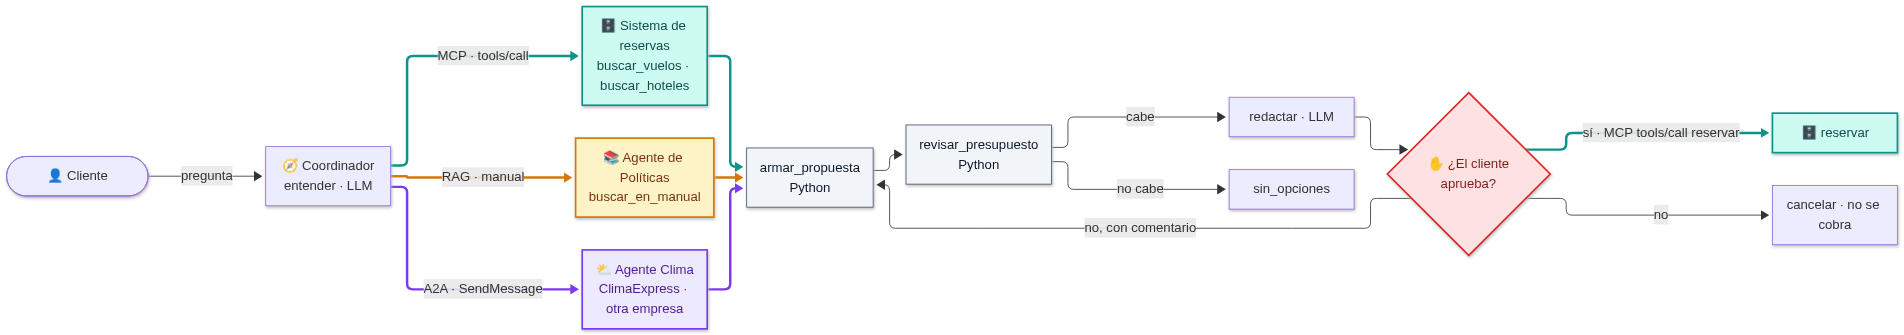

In [4]:
import base64, requests
from pathlib import Path
from IPython.display import Image, display
from langchain_core.runnables.graph_mermaid import draw_mermaid_png   # la que usa get_graph().draw_mermaid_png()

# draw_mermaid_png envía el texto a mermaid.ink codificado en base64. Si la codificación contiene «/»,
# la dirección se rompe y el servicio responde 404. En ese caso repetimos la MISMA petición con base64
# apto para URL (cambia «/» por «_»), que mermaid.ink también entiende.
def dibujar_mermaid(texto, archivo):
    try:
        png = draw_mermaid_png(texto, output_file_path=archivo)
    except ValueError:
        codigo = base64.urlsafe_b64encode(texto.encode('utf-8')).decode('ascii')
        respuesta = requests.get(f'https://mermaid.ink/img/{codigo}?type=png&bgColor=!white', timeout=30)
        respuesta.raise_for_status()
        png = respuesta.content
        Path(archivo).write_bytes(png)
    display(Image(png))

# 🟩 MCP · 🟧 RAG · 🟪 A2A · ⬜ Python · 🟥 humano en el bucle
DIAGRAMA_ARQUITECTURA = '''flowchart LR
    C(["👤 Cliente"]) -->|pregunta| E["🧭 Coordinador<br/>entender · LLM"]
    E -->|"MCP · tools/call"| R["🗄️ Sistema de reservas<br/>buscar_vuelos · buscar_hoteles"]:::mcp
    E -->|"RAG · manual"| P["📚 Agente de Políticas<br/>buscar_en_manual"]:::rag
    E -->|"A2A · SendMessage"| W["⛅ Agente Clima<br/>ClimaExpress · otra empresa"]:::a2a
    R --> A["armar_propuesta<br/>Python"]:::py
    P --> A
    W --> A
    A --> B["revisar_presupuesto<br/>Python"]:::py
    B -->|cabe| D["redactar · LLM"]
    B -->|no cabe| S["sin_opciones"]
    D --> H{"✋ ¿El cliente<br/>aprueba?"}:::humano
    H -->|"sí · MCP tools/call reservar"| X["🗄️ reservar"]:::mcp
    H -->|"no, con comentario"| A
    H -->|"no"| F["cancelar · no se cobra"]
    classDef mcp fill:#ccfbf1,stroke:#0d9488,stroke-width:2px,color:#134e4a
    classDef rag fill:#fef3c7,stroke:#d97706,stroke-width:2px,color:#78350f
    classDef a2a fill:#ede9fe,stroke:#7c3aed,stroke-width:2px,color:#4c1d95
    classDef py fill:#f1f5f9,stroke:#475569,color:#0f172a
    classDef humano fill:#fee2e2,stroke:#dc2626,stroke-width:2px,color:#7f1d1d
    linkStyle 1,4,11 stroke:#0d9488,stroke-width:3px
    linkStyle 2,5 stroke:#d97706,stroke-width:3px
    linkStyle 3,6 stroke:#7c3aed,stroke-width:3px'''

try:
    dibujar_mermaid(DIAGRAMA_ARQUITECTURA, 'diagrama_arquitectura.png')
except Exception:
    print('No se pudo dibujar (¿sin internet?). Pega este texto en https://mermaid.live :')
    print(DIAGRAMA_ARQUITECTURA)

## Paso 3 · ▶️ 🗄️ El sistema de reservas como servidor MCP (simulado)
En el laboratorio 7 el servidor MCP era real (`FastMCP` en el puerto 8001). Aquí lo **imitamos** con una clase pequeña para enfocarnos en la arquitectura, pero respetamos las dos operaciones del protocolo:

| Protocolo MCP | En la simulación |
|---|---|
| `@servidor_mcp.tool()` | `@reservas_mcp.herramienta` |
| `tools/list` | `reservas_mcp.tools_list()` → nombre y docstring de cada herramienta |
| `tools/call` | `reservas_mcp.tools_call(nombre, argumentos)` → anota 🟩 en la bitácora |

Los vuelos y hoteles son **los mismos del reto**, más una `categoria` (estrellas) para poder elegir el mejor hotel que quepa.

> 🔁 Para volverlo real basta con cambiar la clase por `FastMCP` y llamarla con `MultiServerMCPClient`, como en el laboratorio 7.

> **🧩 En palabras simples**
> - **Qué hace esta celda:** crea el sistema de reservas con tres herramientas: buscar vuelos, buscar hoteles y reservar.
> - **Piénsalo como:** la ventanilla de la aerolínea y los hoteles, con un catálogo de servicios pegado en la pared.
> - **Qué vas a ver al ejecutarla:** el catálogo (`tools/list`) con las 3 herramientas.

In [5]:
import unicodedata

def normalizar(texto):              # 'Cartagena ' → 'cartagena' · 'Diciembre' → 'diciembre'
    return unicodedata.normalize('NFKD', texto).encode('ascii', 'ignore').decode().strip().lower()

# Inventario ficticio (los precios del reto). Solo hay disponibilidad para Cartagena.
INVENTARIO = {
    'cartagena': {
        'vuelos': [{'aerolinea': 'Aerolínea Sol',   'precio_por_persona': 420_000},
                   {'aerolinea': 'Aerolínea Brisa', 'precio_por_persona': 350_000}],
        'hoteles': [{'hotel': 'Hostal Centro',  'categoria': 2, 'precio_noche': 180_000},
                    {'hotel': 'Hotel Mar Azul', 'categoria': 4, 'precio_noche': 380_000},
                    {'hotel': 'Hotel Murallas', 'categoria': 5, 'precio_noche': 650_000}],
    },
}
RESERVAS = []        # aquí "se guardan" las reservas confirmadas (en memoria)

class ServidorMCPSimulado:
    '''Imita un servidor MCP: publica herramientas (tools/list) y las ejecuta (tools/call).'''
    def __init__(self, nombre):
        self.nombre, self.herramientas = nombre, {}

    def herramienta(self, funcion):                      # el papel de @servidor_mcp.tool()
        self.herramientas[funcion.__name__] = funcion
        return funcion

    def tools_list(self):
        return [{'name': n, 'description': f.__doc__} for n, f in self.herramientas.items()]

    def tools_call(self, nombre, argumentos):
        # El medio de pago nunca se escribe completo en la bitácora
        visibles = {k: ('****' if k == 'medio_pago' else v) for k, v in argumentos.items()}
        registrar('Coordinador', 'Sistema Reservas', 'MCP', f'tools/call {nombre}', visibles)
        resultado = self.herramientas[nombre](**argumentos)
        registrar('Sistema Reservas', 'Coordinador', 'MCP', f'resultado {nombre}', resultado)
        return resultado

reservas_mcp = ServidorMCPSimulado('Sistema de reservas ViajaFácil')

@reservas_mcp.herramienta
def buscar_vuelos(destino: str, personas: int) -> dict:
    '''Busca vuelos de ida y regreso desde Medellín hacia el destino. Precio por persona en COP.'''
    return {'destino': destino, 'personas': personas,
            'vuelos': INVENTARIO.get(normalizar(destino), {}).get('vuelos', [])}

@reservas_mcp.herramienta
def buscar_hoteles(destino: str, noches: int) -> dict:
    '''Busca hoteles disponibles en el destino. Precio por noche en COP (habitación doble).'''
    return {'destino': destino, 'noches': noches,
            'hoteles': INVENTARIO.get(normalizar(destino), {}).get('hoteles', [])}

@reservas_mcp.herramienta
def reservar(vuelo: str, hotel: str, personas: int, noches: int, total_cop: int, medio_pago: str) -> dict:
    '''Crea la reserva (ficticia). Solo debe llamarse después de que el cliente la aprueba.'''
    codigo = f'VF-{len(RESERVAS) + 1:04d}'
    RESERVAS.append({'codigo': codigo, 'vuelo': vuelo, 'hotel': hotel, 'personas': personas,
                     'noches': noches, 'total_cop': total_cop, 'pago_terminado_en': medio_pago[-4:]})
    return {'codigo': codigo, 'estado': 'confirmada (ficticia)'}

print(f'📋 tools/list de «{reservas_mcp.nombre}»:')
for h in reservas_mcp.tools_list():
    print(f"   • {h['name']}: {h['description']}")

📋 tools/list de «Sistema de reservas ViajaFácil»:
   • buscar_vuelos: Busca vuelos de ida y regreso desde Medellín hacia el destino. Precio por persona en COP.
   • buscar_hoteles: Busca hoteles disponibles en el destino. Precio por noche en COP (habitación doble).
   • reservar: Crea la reserva (ficticia). Solo debe llamarse después de que el cliente la aprueba.


## Paso 4 · ▶️ 📚 El manual de políticas y el RAG
El manual real tendría 50 páginas: no cabe (ni conviene) en el prompt. Hacemos lo del laboratorio 6, versión original:

| Paso del RAG | Aquí |
|---|---|
| 1. Documentos | 8 archivos `.md` ficticios en `manual/` (cancelaciones, equipaje, reembolsos…) |
| 2. Dividir | `RecursiveCharacterTextSplitter` en fragmentos de ~400 caracteres |
| 3. Embeddings | `paraphrase-multilingual-MiniLM-L12-v2` (corre en tu equipo, sin API key) |
| 4. Índice | `InMemoryVectorStore` (en memoria) |
| 5. Buscar | Los 3 fragmentos más parecidos a la pregunta, con su fuente |

Las tres políticas del reto (cancelación 72 h y 30 %, maleta de bodega $90.000, reembolso en 15 días hábiles) están en el manual, con más detalle alrededor.

> **🧩 En palabras simples**
> - **Qué hace esta celda:** escribe el manual ficticio en la carpeta `manual/`.
> - **Piénsalo como:** imprimir el manual de la agencia y ponerlo en una carpeta.
> - **Qué vas a ver al ejecutarla:** `8 archivos en manual/`.

In [6]:
from pathlib import Path

MANUAL = {
'cancelaciones.md': '''# Cancelaciones (política ficticia de ViajaFácil)
## Plazos
La cancelación es gratuita hasta 72 horas antes de la fecha de salida del viaje.
Si el cliente cancela con menos de 72 horas de anticipación, se cobra una penalidad del 30 % del valor total del paquete.
Si el cliente no se presenta al vuelo o al hotel sin cancelar (no show), se cobra el 100 % del valor.
## Cómo cancelar
La cancelación se solicita en la página web, en la línea de atención o en una oficina, indicando el código de reserva.
La agencia envía una confirmación escrita de la cancelación en un máximo de 24 horas.
## Fuerza mayor
Si el viaje no puede realizarse por cierre del aeropuerto, una emergencia médica certificada o una decisión de la autoridad,
no se cobra penalidad y el cliente puede elegir entre un reembolso o un cambio de fecha sin costo.''',

'equipaje.md': '''# Equipaje (política ficticia de ViajaFácil)
## Incluido en el paquete
Cada viajero tiene incluida una maleta de mano de hasta 10 kg y un artículo personal pequeño, como un bolso o un morral.
## Maleta de bodega
La maleta de bodega no está incluida. Cuesta $90.000 por maleta, por trayecto, y puede pesar hasta 23 kg.
Si se compra en el aeropuerto el día del vuelo, el precio sube a $140.000.
## Equipaje especial
Los equipos deportivos (tablas, bicicletas o equipos de buceo) pagan un cargo fijo de $150.000 por trayecto.
Las mascotas pequeñas pueden viajar en cabina en un guacal de hasta 8 kg con un cargo de $200.000 por trayecto.''',

'reembolsos.md': '''# Reembolsos (política ficticia de ViajaFácil)
Los reembolsos se hacen en un máximo de 15 días hábiles, al mismo medio de pago con el que se pagó la reserva.
El valor reembolsado es el total pagado menos la penalidad de cancelación que corresponda.
Los cargos de la maleta de bodega y de los seguros opcionales no son reembolsables una vez iniciado el viaje.
Si el reembolso se origina en una causa de fuerza mayor, se devuelve el 100 % del valor pagado.
La agencia nunca entrega reembolsos en efectivo ni a cuentas de terceros.''',

'cambios_de_fecha.md': '''# Cambios de fecha (política ficticia de ViajaFácil)
Los cambios de fecha se pueden solicitar hasta 48 horas antes de la salida.
Cada cambio tiene un cargo de $80.000 por persona, más la diferencia de tarifa si el nuevo vuelo o el nuevo hotel cuesta más.
Si la nueva tarifa es más barata, la diferencia no se devuelve; queda como saldo a favor por 12 meses.
En temporada alta (del 15 de diciembre al 15 de enero y la Semana Santa) los cambios están sujetos a disponibilidad.''',

'temporada_alta.md': '''# Temporada alta y precios (política ficticia de ViajaFácil)
Diciembre es temporada alta en los destinos de playa del Caribe colombiano, como Cartagena y Santa Marta.
Los precios de una propuesta se garantizan durante 24 horas; después pueden cambiar según la disponibilidad.
Los precios de los paquetes incluyen los impuestos de los tiquetes y del hotel, pero no las propinas ni los traslados.
Se recomienda reservar con al menos 30 días de anticipación para viajes en temporada alta.''',

'documentos_de_viaje.md': '''# Documentos de viaje (política ficticia de ViajaFácil)
Para vuelos nacionales los adultos colombianos viajan con la cédula de ciudadanía original.
Los extranjeros necesitan el pasaporte vigente. Los menores de edad viajan con la tarjeta de identidad o el registro civil.
Los menores que viajen sin uno de sus padres necesitan un permiso autenticado del padre que no viaja.
El nombre de la reserva debe coincidir exactamente con el del documento de identidad.''',

'pagos_y_datos.md': '''# Pagos y datos personales (política ficticia de ViajaFácil)
## Pagos
Se aceptan tarjetas de crédito, tarjetas débito y transferencias. El pago se procesa solo después de que el cliente aprueba la propuesta.
ViajaFácil no almacena el número completo de la tarjeta: el sistema de reservas guarda solo los últimos cuatro dígitos.
## Datos personales
Los datos del cliente se usan únicamente para la reserva. No se comparten con proveedores externos más allá de lo necesario:
por ejemplo, el proveedor de clima solo recibe el destino y el mes del viaje.''',

'seguros_y_asistencia.md': '''# Seguros y asistencia (política ficticia de ViajaFácil)
El seguro de viaje es opcional y cuesta $25.000 por persona por día de viaje.
Cubre la atención médica de urgencias, la pérdida de equipaje hasta $1.500.000 y la cancelación por enfermedad certificada.
La asistencia al viajero funciona las 24 horas en la línea de atención de la agencia.''',
}

CARPETA_MANUAL = Path('manual')
CARPETA_MANUAL.mkdir(exist_ok=True)
for nombre, texto in MANUAL.items():
    (CARPETA_MANUAL / nombre).write_text(texto, encoding='utf-8')
print(f'{len(MANUAL)} archivos en {CARPETA_MANUAL}/')

8 archivos en manual/


> **🧩 En palabras simples**
> - **Qué hace esta celda:** divide el manual en fragmentos, los convierte en números (embeddings) y arma el índice para buscar.
> - **Piénsalo como:** subrayar el manual por párrafos y hacer un índice al final para encontrar rápido cada tema.
> - **Qué vas a ver al ejecutarla:** cuántos fragmentos hay y los 3 más parecidos a «¿hasta cuándo puedo cancelar gratis?».

In [7]:
from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings

# 1) CARGAR: un Document por archivo, con su fuente
documentos = [Document(page_content=p.read_text(encoding='utf-8'), metadata={'fuente': p.name})
              for p in sorted(CARPETA_MANUAL.glob('*.md'))]

# 2) DIVIDIR: fragmentos de ~400 caracteres, respetando párrafos y líneas
fragmentos = RecursiveCharacterTextSplitter(chunk_size=400, chunk_overlap=50).split_documents(documentos)

# 3) EMBEDDINGS e 4) ÍNDICE en memoria
embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2',
                                   encode_kwargs={'normalize_embeddings': True})
indice = InMemoryVectorStore.from_documents(fragmentos, embeddings)
print(f'{len(documentos)} documentos → {len(fragmentos)} fragmentos en el índice\n')

# 5) BUSCAR: los k fragmentos más parecidos (score más ALTO = más parecido)
def buscar(consulta, k=3):
    return indice.similarity_search_with_score(consulta, k=k)

for doc, score in buscar('¿Hasta cuándo puedo cancelar gratis?'):
    print(f"[{doc.metadata['fuente']}] score {score:.2f} · {doc.page_content[:90]}…")

C:\Users\A47x\OneDrive\A47x\ARQUITECTURAS-EN-INTELIGENCIA-ARTIFICIAL-MULTIAGENTICA\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4153.52it/s]

8 documentos → 16 fragmentos en el índice

[cancelaciones.md] score 0.74 · # Cancelaciones (política ficticia de ViajaFácil)
## Plazos
La cancelación es gratuita has…
[cancelaciones.md] score 0.66 · ## Cómo cancelar
La cancelación se solicita en la página web, en la línea de atención o en…
[cambios_de_fecha.md] score 0.42 · # Cambios de fecha (política ficticia de ViajaFácil)
Los cambios de fecha se pueden solici…


El **Agente de Políticas** es el `crear_especialista('politicas')` del laboratorio 6: un `create_agent` con **una sola herramienta**, `buscar_en_manual`, e instrucciones de responder solo con los fragmentos y citar la fuente.

> **🧩 En palabras simples**
> - **Qué hace esta celda:** crea el Agente de Políticas y le hace una pregunta de prueba.
> - **Piénsalo como:** un empleado que, antes de responder, siempre busca en el manual y dice en qué página lo leyó.
> - **Qué vas a ver al ejecutarla:** una respuesta con las 72 horas y la cita `[cancelaciones.md]`.

In [8]:
from groq import BadRequestError
from langchain.tools import tool
from langchain.agents import create_agent
from langchain.agents.middleware import ModelRetryMiddleware

@tool
def buscar_en_manual(consulta: str) -> str:
    '''Busca en el manual de políticas de ViajaFácil (cancelaciones, equipaje, reembolsos, cambios de fecha,
    temporada alta, documentos de viaje, pagos y seguros). Devuelve fragmentos con su fuente.'''
    resultados = buscar(consulta)
    registrar('Agente Políticas', 'Agente Políticas', 'RAG', f'busca: «{consulta[:40]}»',
              [d.metadata['fuente'] for d, _ in resultados])
    return '\n\n'.join(f"[{d.metadata['fuente']}] {d.page_content}" for d, _ in resultados)

def crear_agente_politicas():
    # Si Groq no logra interpretar la llamada a herramienta (error 400), la repetimos (como en el 06a)
    reintento = ModelRetryMiddleware(max_retries=2, retry_on=(BadRequestError,), on_failure='error')
    return create_agent(
        model=nuevo_llm('Políticas'), tools=[buscar_en_manual], middleware=[reintento],
        system_prompt=('Eres el Agente de Políticas de la agencia de viajes ficticia ViajaFácil. '
                       'SIEMPRE usa buscar_en_manual antes de responder (una búsqueda por pregunta). '
                       'Responde SOLO con información de los fragmentos y cita la fuente entre corchetes, '
                       'ej. [cancelaciones.md]. Si el manual no lo dice, responde: "El manual no tiene esa información". '
                       'Máximo 5 frases.'))

print(crear_agente_politicas().invoke({'messages': [('user', '¿Hasta cuándo puedo cancelar gratis?')]})['messages'][-1].text)

La cancelación es gratuita hasta **72 horas antes** de la fecha de salida del viaje. [cancelaciones.md]


## Paso 5 · ▶️ ⛅ El Agente Clima de otra empresa (A2A simulado)
ClimaExpress es **otra empresa**: ViajaFácil no ve su código, solo su **Agent Card** y la forma de enviarle mensajes. Imitamos las piezas del laboratorio 7:

| A2A real (lab 7) | En la simulación |
|---|---|
| Agent Card en `/.well-known/agent-card.json` | El diccionario `AGENT_CARD_CLIMA` |
| `SendMessage` con `role: ROLE_USER` y `parts` | `enviar_a2a_simulado(texto)` arma el mismo mensaje |
| Respuesta `Message` con `role: ROLE_AGENT` | El texto que redacta el agente de ClimaExpress |

Por dentro, ClimaExpress es un agente con su **propio LLM** y su herramienta `consultar_clima`. Por eso cada consulta cuesta **llamadas al LLM**: es la pregunta de la socialización («¿el Agente Clima necesita ser un agente?»). La bandera `CLIMA_COMO_AGENTE` permite compararlo con una herramienta simple (ver el reto al final).

> **🧩 En palabras simples**
> - **Qué hace esta celda:** crea el agente de clima de la otra empresa y la forma de enviarle mensajes.
> - **Piénsalo como:** llamar a un servicio externo que solo conoces por su tarjeta de presentación.
> - **Qué vas a ver al ejecutarla:** la Agent Card y la respuesta del agente para Cartagena en diciembre.

In [9]:
import uuid

CLIMA_COMO_AGENTE = True      # True = agente por A2A (con LLM) · False = herramienta simple (reto opcional)

# Datos de ClimaExpress (ficticios)
CLIMA_FICTICIO = {
    ('cartagena', 'diciembre'): {'resumen': 'soleado, con brisa y poca lluvia', 'max_c': 31, 'min_c': 25, 'lluvia': 'baja'},
    ('cartagena', 'octubre'):   {'resumen': 'caluroso y con lluvias en la tarde', 'max_c': 31, 'min_c': 25, 'lluvia': 'alta'},
}

# La tarjeta de presentación pública de ClimaExpress (lo único que ViajaFácil conoce)
AGENT_CARD_CLIMA = {
    'name': 'Agente Clima · ClimaExpress',
    'description': 'Pronóstico de temporada por destino y mes. No conoce clientes ni precios.',
    'url': 'https://climaexpress.example/a2a  (simulado)',
    'skills': [{'id': 'pronostico', 'examples': ['¿Qué clima hace en Cartagena en diciembre?']}],
}

# ── Lo de abajo vive en la otra empresa: ViajaFácil no lo ve ──────────
@tool
def consultar_clima(destino: str, mes: str) -> dict:
    '''Consulta el clima esperado (ficticio) en un destino y mes.'''
    registrar('Agente Clima', 'Agente Clima', 'Python', 'herramienta consultar_clima', {'destino': destino, 'mes': mes})
    return CLIMA_FICTICIO.get((normalizar(destino), normalizar(mes)), {'error': 'sin datos para ese destino y mes'})

def crear_agente_clima_externo():
    return create_agent(model=nuevo_llm('Clima'), tools=[consultar_clima],
                        system_prompt='Eres el agente de ClimaExpress. Usa consultar_clima y responde en máximo 2 frases '
                                      'con los datos de la herramienta. No inventes datos.')

# ── Lo que hace ViajaFácil: enviar un mensaje A2A y leer la respuesta ──
def enviar_a2a_simulado(texto):
    mensaje = {'messageId': str(uuid.uuid4()), 'role': 'ROLE_USER', 'parts': [{'text': texto}]}
    registrar('Coordinador', 'Agente Clima', 'A2A', 'SendMessage', texto)
    r = crear_agente_clima_externo().invoke({'messages': [('user', mensaje['parts'][0]['text'])]})
    respuesta = {'role': 'ROLE_AGENT', 'parts': [{'text': r['messages'][-1].text}]}
    registrar('Agente Clima', 'Coordinador', 'A2A', 'Message (respuesta)', respuesta['parts'][0]['text'])
    return respuesta['parts'][0]['text']

print('📇', json.dumps(AGENT_CARD_CLIMA, ensure_ascii=False))
print('⛅', enviar_a2a_simulado('¿Qué clima hace en Cartagena en diciembre?'))

📇 {"name": "Agente Clima · ClimaExpress", "description": "Pronóstico de temporada por destino y mes. No conoce clientes ni precios.", "url": "https://climaexpress.example/a2a  (simulado)", "skills": [{"id": "pronostico", "examples": ["¿Qué clima hace en Cartagena en diciembre?"]}]}


⛅ En diciembre, Cartagena es soleado con brisa, tiene poca lluvia y temperaturas entre 25 °C y 31 °C.


## Paso 6 · ▶️ El grafo: estado, nodos y aristas
### El estado (lo que viaja por el flujo)
| Campo | Lo escribe | Lo leen |
|---|---|---|
| `solicitud` (destino, mes, días, noches, personas, presupuesto, preguntas) | `entender` | todos, **cada uno solo lo que necesita** |
| `vuelos`, `hoteles` | `reservas` (MCP) | `armar_propuesta`, `revisar_presupuesto` |
| `texto_politicas` | `politicas` (RAG) | `redactar` |
| `texto_clima` | `clima` (A2A) | `redactar` |
| `propuesta`, `revision` | `armar_propuesta`, `revisar_presupuesto` (Python) | `redactar`, `aprobacion_humana`, `reservar` |
| `decision`, `descartadas` | `aprobacion_humana` | la ruta siguiente y `armar_propuesta` |

### Los nodos
| Nodo | Tipo | LLM | Qué recibe (y qué no) |
|---|---|---|---|
| `entender` | 🟦 LLM | 1 | La pregunta. Devuelve un `Solicitud` validado con **Pydantic**; las noches las calcula Python |
| `reservas` | 🟩 MCP | 0 | Destino, personas y noches. **No** el presupuesto |
| `politicas` | 🟧 RAG | 2–3 | Solo las preguntas sobre políticas. **No** el presupuesto ni el destino |
| `clima` | 🟪 A2A | ~2 | Solo destino y mes: sale hacia **otra empresa** |
| `armar_propuesta` | ⬜ Python | 0 | Elige el hotel de **mayor categoría** que quepa; a igual categoría, el total más bajo |
| `revisar_presupuesto` | ⬜ Python | 0 | Recalcula el total desde los precios y lo compara con el presupuesto |
| `redactar` | 🟦 LLM | 1 | Las cifras ya calculadas, el clima y las políticas. **No** el medio de pago |
| `aprobacion_humana` | 🟥 `interrupt()` | 0 | La propuesta. Pausa el flujo hasta que el cliente decide |
| `reservar` | 🟩 MCP | 0 | **El único** que usa el medio de pago |
| `cancelar`, `sin_opciones` | ⬜ Python | 0 | Cierran el flujo sin reservar |

### Las aristas
- `entender` → **`reservas`, `politicas` y `clima` a la vez** (abanico) → `armar_propuesta` espera a **las tres** (`add_edge([...], 'armar_propuesta')`).
- Después de `aprobacion_humana`: aprueba → `reservar`; rechaza con comentario → `armar_propuesta` (sin repetir las búsquedas); rechaza sin comentario → `cancelar`.

> **🧩 En palabras simples**
> - **Qué hace esta celda:** define el estado, los once nodos y las aristas del flujo, y lo compila con memoria (checkpointer).
> - **Piénsalo como:** el procedimiento escrito de la agencia: quién hace qué, en qué orden y dónde se espera la firma del cliente.
> - **Qué vas a ver al ejecutarla:** `Grafo compilado con 11 nodos.`

In [10]:
from typing import TypedDict
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import interrupt, Command

# ── Contratos validados con Pydantic (como en el laboratorio 2) ─────
class Solicitud(BaseModel):
    destino: str = Field(description='Ciudad de destino, ej. Cartagena')
    mes: str = Field(description='Mes del viaje en español y en minúscula, ej. diciembre')
    dias: int = Field(gt=0, description='Duración del viaje en días')
    personas: int = Field(gt=0, description='Número de viajeros; "con mi pareja" son 2')
    presupuesto_cop: int = Field(gt=0, description='Presupuesto TOTAL en pesos; "3 millones" = 3000000')
    preguntas_politicas: list[str] = Field(default_factory=list,
        description='Preguntas del cliente sobre cancelación, equipaje, reembolsos u otras políticas; lista vacía si no hay')

class DecisionHumana(BaseModel):
    aprobado: bool
    comentario: str = ''

class Estado(TypedDict, total=False):
    pregunta: str
    solicitud: dict
    vuelos: list
    hoteles: list
    texto_politicas: str
    texto_clima: str
    propuesta: dict
    revision: dict
    texto_propuesta: str
    intentos: int
    decision: dict
    descartadas: list          # combinaciones que el cliente ya rechazó
    tope_total: int            # si pidió "más barato": el total debe quedar por debajo de este valor
    respuesta_final: str

MAX_PROPUESTAS = 3
MEDIO_PAGO_FICTICIO = 'tarjeta-ficticia-0000'      # solo lo usa el nodo reservar; nunca llega a un LLM
TEMAS_SIEMPRE = ['¿Hasta cuándo se puede cancelar gratis y qué pasa si se cancela después?',
                 '¿Qué equipaje incluye el viaje y cuánto cuesta la maleta de bodega?']

# ── 1) entender (LLM): de texto libre a datos validados ─────────────
def entender(estado):
    registrar('Coordinador', 'Coordinador', 'LLM', 'entender la solicitud')
    extractor = nuevo_llm('Coordinador').with_structured_output(Solicitud)
    s = extractor.invoke([('system', 'Extrae los datos de la solicitud de viaje del cliente. No inventes datos.'),
                          ('user', estado['pregunta'])]).model_dump()
    s['noches'] = max(1, s['dias'] - 1)                  # Python, no el LLM: 4 días = 3 noches
    registrar('Coordinador', 'Coordinador', 'Python', 'solicitud validada', s)
    return {'solicitud': s, 'intentos': 0, 'descartadas': []}

# ── 2a) reservas (MCP): solo destino, personas y noches ─────────────
def reservas(estado):
    s = estado['solicitud']
    vuelos = reservas_mcp.tools_call('buscar_vuelos', {'destino': s['destino'], 'personas': s['personas']})['vuelos']
    hoteles = reservas_mcp.tools_call('buscar_hoteles', {'destino': s['destino'], 'noches': s['noches']})['hoteles']
    return {'vuelos': vuelos, 'hoteles': hoteles}

# ── 2b) politicas (RAG): solo las preguntas, sin presupuesto ni destino ─
def politicas(estado):
    preguntas = list(dict.fromkeys(estado['solicitud']['preguntas_politicas'] + TEMAS_SIEMPRE))   # sin repetidas
    pedido = 'Responde cada pregunta con el manual:\n' + '\n'.join(f'- {p}' for p in preguntas)
    registrar('Coordinador', 'Agente Políticas', 'RAG', 'consulta el manual', pedido)
    texto = crear_agente_politicas().invoke({'messages': [('user', pedido)]})['messages'][-1].text
    registrar('Agente Políticas', 'Coordinador', 'RAG', 'responde con citas', texto)
    return {'texto_politicas': texto}

# ── 2c) clima (A2A): solo destino y mes salen hacia la otra empresa ──
def clima(estado):
    s = estado['solicitud']
    if CLIMA_COMO_AGENTE:
        texto = enviar_a2a_simulado(f"¿Qué clima hace en {s['destino']} en {s['mes']}?")
    else:   # reto: la misma consulta como herramienta simple, sin LLM
        texto = json.dumps(consultar_clima.invoke({'destino': s['destino'], 'mes': s['mes']}), ensure_ascii=False)
    return {'texto_clima': texto}

# ── 3) armar_propuesta (Python): combina y elige ─────────────────────
def armar_propuesta(estado):
    s, tope = estado['solicitud'], estado.get('tope_total')
    opciones = []
    for v in estado['vuelos']:
        for h in estado['hoteles']:
            total = v['precio_por_persona'] * s['personas'] + h['precio_noche'] * s['noches']
            combinacion = f"{v['aerolinea']} + {h['hotel']}"
            if (total <= s['presupuesto_cop'] and combinacion not in estado.get('descartadas', [])
                    and (tope is None or total < tope)):
                opciones.append({'vuelo': v['aerolinea'], 'hotel': h['hotel'], 'categoria': h['categoria'],
                                 'vuelos_cop': v['precio_por_persona'] * s['personas'],
                                 'hotel_cop': h['precio_noche'] * s['noches'], 'total_cop': total})
    # Criterio: el hotel de mayor categoría que quepa; a igual categoría, el total más bajo
    opciones.sort(key=lambda o: (-o['categoria'], o['total_cop']))
    propuesta = opciones[0] if opciones else {}
    registrar('Coordinador', 'Coordinador', 'Python', f'armar_propuesta ({len(opciones)} caben)',
              propuesta or 'ninguna combinación cumple')
    return {'propuesta': propuesta}

# ── 4) revisar_presupuesto (Python): una segunda verificación, independiente ─
def revisar_presupuesto(estado):
    p, s = estado['propuesta'], estado['solicitud']
    if not p:
        revision = {'dentro_del_presupuesto': False}
    else:
        vuelo = next(v for v in estado['vuelos'] if v['aerolinea'] == p['vuelo'])
        hotel = next(h for h in estado['hoteles'] if h['hotel'] == p['hotel'])
        total = vuelo['precio_por_persona'] * s['personas'] + hotel['precio_noche'] * s['noches']
        revision = {'total_cop': total, 'presupuesto_cop': s['presupuesto_cop'], 'sobrante_cop': s['presupuesto_cop'] - total,
                    'dentro_del_presupuesto': total == p['total_cop'] and total <= s['presupuesto_cop']}
    registrar('Coordinador', 'Coordinador', 'Python', 'revisar_presupuesto', revision)
    return {'revision': revision}

def ruta_presupuesto(estado):
    return 'redactar' if estado['revision']['dentro_del_presupuesto'] else 'sin_opciones'

# ── 5) redactar (LLM): cifras de Python + clima + políticas → texto ──
def redactar(estado):
    s, p, r = estado['solicitud'], estado['propuesta'], estado['revision']
    datos = {'destino': s['destino'], 'mes': s['mes'], 'personas': s['personas'], 'noches': s['noches'],
             'vuelo': p['vuelo'], 'vuelos': cop(p['vuelos_cop']), 'hotel': f"{p['hotel']} ({p['categoria']} estrellas)",
             'hotel_total': cop(p['hotel_cop']), 'total': cop(r['total_cop']), 'presupuesto': cop(r['presupuesto_cop']),
             'sobrante': cop(r['sobrante_cop']), 'clima': estado['texto_clima'], 'politicas': estado['texto_politicas']}
    registrar('Coordinador', 'Coordinador', 'LLM', 'redactar propuesta')
    texto = nuevo_llm('Coordinador').invoke([
        ('system', 'Eres el Coordinador de ViajaFácil. Redacta para el cliente, en español y en máximo 10 líneas, la '
                   'propuesta: vuelo, hotel, desglose, total, presupuesto y sobrante (copia EXACTAMENTE las cifras), el '
                   'clima y las políticas clave. Cita fuentes SOLO en las políticas, copiando tal cual las que vienen en '
                   '"politicas" (ej. [cancelaciones.md]); no pongas citas en vuelos, hotel, clima ni cifras. '
                   'Termina preguntando si aprueba la reserva. No digas que ya está reservada.'),
        ('user', json.dumps(datos, ensure_ascii=False))]).text
    return {'texto_propuesta': texto, 'intentos': estado.get('intentos', 0) + 1}

# ── 6) aprobacion_humana: pausa REAL hasta que el cliente decide ─────
def aprobacion_humana(estado):
    # Al reanudar, LangGraph vuelve a ejecutar este nodo desde el inicio: nada antes de interrupt() debe tener efectos
    valor = interrupt({'texto': estado['texto_propuesta'], 'propuesta': estado['propuesta'], 'intento': estado['intentos']})
    decision = DecisionHumana.model_validate(valor)
    registrar('Cliente', 'Coordinador', 'Humano',
              '✋ aprueba' if decision.aprobado else f'✋ rechaza: {decision.comentario or "sin comentario"}')
    cambios = {'decision': decision.model_dump()}
    if not decision.aprobado and decision.comentario:
        p = estado['propuesta']
        cambios['descartadas'] = estado.get('descartadas', []) + [f"{p['vuelo']} + {p['hotel']}"]
        if any(palabra in normalizar(decision.comentario) for palabra in ('barat', 'econom', 'menos')):
            cambios['tope_total'] = p['total_cop']
    return cambios

def ruta_decision(estado):
    d = estado['decision']
    if d['aprobado']:
        return 'reservar'
    if d['comentario'] and estado['intentos'] < MAX_PROPUESTAS:
        return 'armar_propuesta'
    return 'cancelar'

# ── 7) Los tres finales ─────────────────────────────────────────────
def nodo_reservar(estado):
    p, s = estado['propuesta'], estado['solicitud']
    r = reservas_mcp.tools_call('reservar', {'vuelo': p['vuelo'], 'hotel': p['hotel'], 'personas': s['personas'],
                                             'noches': s['noches'], 'total_cop': p['total_cop'],
                                             'medio_pago': MEDIO_PAGO_FICTICIO})
    texto = f"✅ Reserva {r['codigo']} confirmada (ficticia): {p['vuelo']} + {p['hotel']} por {cop(p['total_cop'])}."
    registrar('Coordinador', 'Cliente', 'Usuario', 'confirmación', texto)
    return {'respuesta_final': texto}

def cancelar(estado):
    texto = '❌ Reserva no realizada. No se cobró nada.'
    registrar('Coordinador', 'Cliente', 'Usuario', 'cancelación', texto)
    return {'respuesta_final': texto}

def sin_opciones(estado):
    texto = 'No encontré una combinación de vuelo y hotel que cumpla tu presupuesto y tus condiciones. No se reservó nada.'
    registrar('Coordinador', 'Cliente', 'Usuario', 'sin opciones', texto)
    return {'respuesta_final': texto}

# ── El grafo ────────────────────────────────────────────────────────
g = StateGraph(Estado)
for nombre, funcion in [('entender', entender), ('reservas', reservas), ('politicas', politicas), ('clima', clima),
                        ('armar_propuesta', armar_propuesta), ('revisar_presupuesto', revisar_presupuesto),
                        ('redactar', redactar), ('aprobacion_humana', aprobacion_humana),
                        ('reservar', nodo_reservar), ('cancelar', cancelar), ('sin_opciones', sin_opciones)]:
    g.add_node(nombre, funcion)

g.add_edge(START, 'entender')
for rama in ['reservas', 'politicas', 'clima']:
    g.add_edge('entender', rama)                                         # abanico: las tres a la vez
g.add_edge(['reservas', 'politicas', 'clima'], 'armar_propuesta')       # espera a las tres
g.add_edge('armar_propuesta', 'revisar_presupuesto')
g.add_conditional_edges('revisar_presupuesto', ruta_presupuesto, ['redactar', 'sin_opciones'])
g.add_edge('redactar', 'aprobacion_humana')
g.add_conditional_edges('aprobacion_humana', ruta_decision, ['reservar', 'armar_propuesta', 'cancelar'])
for fin in ['reservar', 'cancelar', 'sin_opciones']:
    g.add_edge(fin, END)

app = g.compile(checkpointer=InMemorySaver())     # el checkpointer guarda el caso mientras espera al cliente

# Ejecuta (o reanuda) el flujo de un caso; si se pausa, lo anota en la bitácora
def ejecutar(entrada, hilo):
    resultado = app.invoke(entrada, {'configurable': {'thread_id': hilo}})
    if '__interrupt__' in resultado:
        registrar('Coordinador', 'Cliente', 'Humano', '⏸️ espera aprobación', resultado['__interrupt__'][0].value['propuesta'])
    return resultado

print(f"Grafo compilado con {len(app.get_graph().nodes) - 2} nodos.")

Grafo compilado con 11 nodos.


## Paso 7 · ▶️ Dibujar el grafo con `draw_mermaid_png()`
La misma celda de los laboratorios anteriores, a través de `dibujar_mermaid` (paso 2). Fíjate en:
- El **abanico**: de `entender` salen tres flechas que vuelven a unirse en `armar_propuesta`.
- Las flechas **punteadas** son condicionales: el presupuesto (`redactar` o `sin_opciones`) y la decisión del cliente (`reservar`, `armar_propuesta` o `cancelar`).
- El **ciclo** `aprobacion_humana → armar_propuesta`: así se arma otra propuesta sin repetir las búsquedas.

La imagen queda en `grafo_flujo.png`.

> **🧩 En palabras simples**
> - **Qué hace esta celda:** dibuja el grafo que LangGraph construyó a partir del código.
> - **Piénsalo como:** la radiografía del procedimiento: el dibujo sale del código, no de una presentación.
> - **Qué vas a ver al ejecutarla:** el grafo con sus 11 nodos.

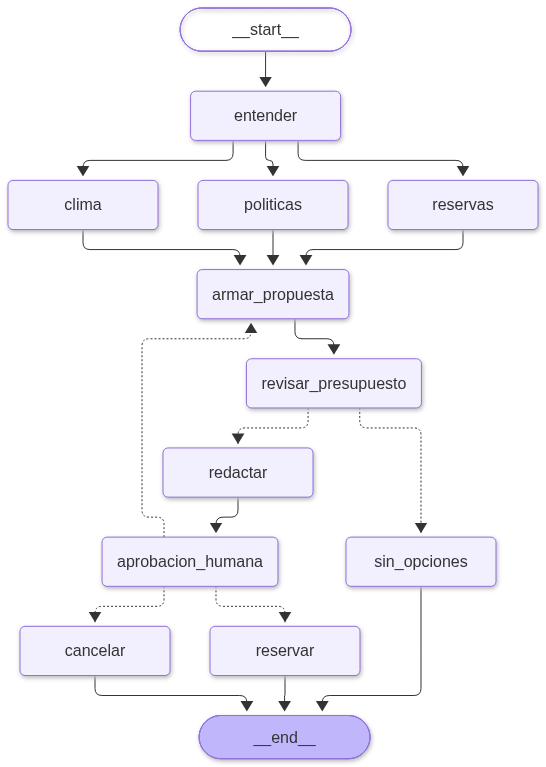

In [11]:
try:
    dibujar_mermaid(app.get_graph().draw_mermaid(), 'grafo_flujo.png')    # = get_graph().draw_mermaid_png()
except Exception:
    print(app.get_graph().draw_mermaid())    # pégalo en https://mermaid.live

## Paso 8 · ▶️ La pregunta principal: el flujo se pausa antes de reservar
Cada caso tiene su `thread_id` (como en el laboratorio 2): con él, el checkpointer guarda dónde quedó el flujo.

**📤 Salida esperada:**
- En la bitácora, las tres ramas (🟩 MCP, 🟧 RAG, 🟪 A2A) **intercaladas**, porque corren a la vez.
- La propuesta: **Aerolínea Brisa + Hotel Murallas** (5 estrellas) por **$2.650.000**, sobrante de $350.000.
- `⏸️ Pausado en: ('aprobacion_humana',)` y **0 reservas**.
- Unas **7 llamadas al LLM**: Coordinador 2 (entender y redactar), Políticas 2–3 (una búsqueda por pregunta), Clima 2.

> **🧩 En palabras simples**
> - **Qué hace esta celda:** le hace la pregunta principal al sistema y se detiene justo antes de reservar.
> - **Piénsalo como:** el asesor arma la cotización y espera la firma del cliente.
> - **Qué vas a ver al ejecutarla:** la tabla de mensajes, la propuesta, que el flujo quedó en pausa y el número de llamadas al LLM.

In [12]:
import pandas as pd

def mostrar_bitacora():
    with pd.option_context('display.max_colwidth', 80):
        display(pd.DataFrame(BITACORA)[['de', 'para', 'tipo', 'accion', 'detalle']])

PREGUNTA = ('Quiero ir a Cartagena 4 días en diciembre con mi pareja, presupuesto de 3 millones. '
            '¿Qué me recomiendas? ¿Y si cancelo, qué pasa?')

BITACORA.clear(); CONTADOR.reiniciar()
HILO_1 = 'caso-1'
registrar('Cliente', 'Coordinador', 'Usuario', 'pregunta', PREGUNTA)
resultado = ejecutar({'pregunta': PREGUNTA}, HILO_1)

mostrar_bitacora()
print('\n📝 PROPUESTA\n' + resultado['__interrupt__'][0].value['texto'])
print('\n⏸️ Pausado en:', app.get_state({'configurable': {'thread_id': HILO_1}}).next)
print('🗄️ Reservas hechas hasta ahora:', len(RESERVAS))
print('📊', CONTADOR.resumen())
LLAMADAS_CASO_1 = CONTADOR.llamadas

,de,para,tipo,accion,detalle
0,Cliente,Coordinador,Usuario,pregunta,"Quiero ir a Cartagena 4 días en diciembre con mi pareja, presupuesto de 3 mi..."
1,Coordinador,Coordinador,LLM,entender la solicitud,
2,Coordinador,Coordinador,Python,solicitud validada,"{""destino"": ""Cartagena"", ""mes"": ""diciembre"", ""dias"": 4, ""personas"": 2, ""pres..."
3,Coordinador,Agente Clima,A2A,SendMessage,¿Qué clima hace en Cartagena en diciembre?
4,Coordinador,Sistema Reservas,MCP,tools/call buscar_vuelos,"{""destino"": ""Cartagena"", ""personas"": 2}"
5,Sistema Reservas,Coordinador,MCP,resultado buscar_vuelos,"{""destino"": ""Cartagena"", ""personas"": 2, ""vuelos"": [{""aerolinea"": ""Aerolínea ..."
6,Coordinador,Sistema Reservas,MCP,tools/call buscar_hoteles,"{""destino"": ""Cartagena"", ""noches"": 3}"
7,Sistema Reservas,Coordinador,MCP,resultado buscar_hoteles,"{""destino"": ""Cartagena"", ""noches"": 3, ""hoteles"": [{""hotel"": ""Hostal Centro"",..."
8,Coordinador,Agente Políticas,RAG,consulta el manual,"Responde cada pregunta con el manual:\n- ¿Y si cancelo, qué pasa?\n- ¿Hasta ..."
9,Agente Clima,Agente Clima,Python,herramienta consultar_clima,"{""destino"": ""Cartagena"", ""mes"": ""diciembre""}"



📝 PROPUESTA
**Vuelo:** Aerolínea Brisa – $700.000  
**Hotel:** Hotel Murallas (5 estrellas) – $1.950.000 (3 noches)  
**Desglose:** Vuelo $700.000 + Hotel $1.950.000 = **$2.650.000**  
**Presupuesto:** $3.000.000 – **Sobrante:** $350.000  
**Clima en diciembre:** Soleado con brisa, poca lluvia y temperaturas entre 25 °C y 31 °C.  

**Políticas clave:**  
- Cancelación gratuita hasta 72 h antes; después penalidad del 30 % del paquete【cancelaciones.md】.  
- Penalidad del 30 % se descuenta del reembolso; resto devuelto en máximo 15 días hábiles【reembolsos.md】.  
- Cada viajero incluye una maleta de mano de hasta 10 kg y un artículo personal pequeño【equipaje.md】.  

¿Aprueba la reserva?

⏸️ Pausado en: ('aprobacion_humana',)
🗄️ Reservas hechas hasta ahora: 0
📊 7 llamadas al LLM · 3891 tokens  (Coordinador: 2 · Clima: 2 · Políticas: 3)


**🤔 Observa:** la celda **terminó**, pero el caso no se perdió: está guardado en el checkpointer, esperando. Nadie puede reservar mientras tanto, porque `reservar` solo es alcanzable desde `aprobacion_humana`.

## Paso 9 · ▶️ El cliente aprueba
`Command(resume=...)` entrega la decisión al `interrupt()` que estaba esperando, con el mismo `thread_id`.

**📤 Salida esperada:** `✅ Reserva VF-0001 confirmada (ficticia): Aerolínea Brisa + Hotel Murallas por $2.650.000`, sin llamadas nuevas al LLM.

> **🧩 En palabras simples**
> - **Qué hace esta celda:** le dice al flujo pausado que el cliente aprobó.
> - **Piénsalo como:** el cliente firma la cotización y el asesor confirma la reserva.
> - **Qué vas a ver al ejecutarla:** la confirmación con el código VF-0001.

In [13]:
antes = CONTADOR.llamadas
decision = DecisionHumana(aprobado=True).model_dump()        # validamos ANTES de enviar
resultado = ejecutar(Command(resume=decision), HILO_1)

print(resultado['respuesta_final'])
print('🗄️ Reservas:', RESERVAS)
BITACORA_CASO_1 = list(BITACORA)                             # la guardamos para las comprobaciones
print(f'📊 Llamadas nuevas al LLM al reservar: {CONTADOR.llamadas - antes}')

✅ Reserva VF-0001 confirmada (ficticia): Aerolínea Brisa + Hotel Murallas por $2.650.000.
🗄️ Reservas: [{'codigo': 'VF-0001', 'vuelo': 'Aerolínea Brisa', 'hotel': 'Hotel Murallas', 'personas': 2, 'noches': 3, 'total_cop': 2650000, 'pago_terminado_en': '0000'}]
📊 Llamadas nuevas al LLM al reservar: 0


## Paso 10 · ▶️ Otro caso: el cliente rechaza
Probamos los otros desenlaces en un caso nuevo (`caso-2`):

1. Rechaza con el comentario **«algo más barato»** → se descarta Brisa + Murallas y se pide un total menor que $2.650.000 → nueva propuesta: **Aerolínea Brisa + Hotel Mar Azul**, $1.840.000. Solo cuesta **1** llamada nueva (`redactar`): las búsquedas no se repiten.
2. Rechaza **sin comentario** → `cancelar`: no se reserva ni se cobra.

> **🧩 En palabras simples**
> - **Qué hace esta celda:** simula un cliente que pide algo más barato y luego desiste.
> - **Piénsalo como:** el cliente pide otra cotización y al final decide no viajar.
> - **Qué vas a ver al ejecutarla:** la segunda propuesta (Hotel Mar Azul) y la cancelación; las reservas siguen siendo 1.

In [14]:
BITACORA.clear(); CONTADOR.reiniciar()
HILO_2 = 'caso-2'
registrar('Cliente', 'Coordinador', 'Usuario', 'pregunta', PREGUNTA)
r1 = ejecutar({'pregunta': PREGUNTA}, HILO_2)
print('1ª propuesta:', r1['__interrupt__'][0].value['propuesta'])
llamadas_primera = CONTADOR.llamadas

r2 = ejecutar(Command(resume=DecisionHumana(aprobado=False, comentario='algo más barato').model_dump()), HILO_2)
print('2ª propuesta:', r2['__interrupt__'][0].value['propuesta'])
print(f'   llamadas nuevas al LLM para re-proponer: {CONTADOR.llamadas - llamadas_primera}')

r3 = ejecutar(Command(resume=DecisionHumana(aprobado=False).model_dump()), HILO_2)
print('\n' + r3['respuesta_final'])
print('🗄️ Reservas (siguen siendo las del caso 1):', len(RESERVAS))

1ª propuesta: {'vuelo': 'Aerolínea Brisa', 'hotel': 'Hotel Murallas', 'categoria': 5, 'vuelos_cop': 700000, 'hotel_cop': 1950000, 'total_cop': 2650000}


2ª propuesta: {'vuelo': 'Aerolínea Brisa', 'hotel': 'Hotel Mar Azul', 'categoria': 4, 'vuelos_cop': 700000, 'hotel_cop': 1140000, 'total_cop': 1840000}
   llamadas nuevas al LLM para re-proponer: 1

❌ Reserva no realizada. No se cobró nada.
🗄️ Reservas (siguen siendo las del caso 1): 1


## Paso 11 · ▶️ Comprobaciones
Los números los calcula Python, pero las rutas de los agentes y la redacción las decide un LLM: por eso **comprobamos** en lugar de suponer.

> **🧩 En palabras simples**
> - **Qué hace esta celda:** revisa que el sistema hizo lo que el diseño promete.
> - **Piénsalo como:** la lista de chequeo antes de entregar el trabajo.
> - **Qué vas a ver al ejecutarla:** una lista de ✅.

In [15]:
import re

estado_1 = app.get_state({'configurable': {'thread_id': HILO_1}}).values
estado_2 = app.get_state({'configurable': {'thread_id': HILO_2}}).values
cifras = re.sub(r'\D', '', estado_1['texto_propuesta'])       # "$2.650.000" → "2650000"
tipos_caso_1 = {e['tipo'] for e in BITACORA_CASO_1}

comprobaciones = {
    'La solicitud se entendió: Cartagena, 2 personas, 3 noches, $3.000.000':
        (normalizar(estado_1['solicitud']['destino']), estado_1['solicitud']['personas'],
         estado_1['solicitud']['noches'], estado_1['solicitud']['presupuesto_cop']) == ('cartagena', 2, 3, 3_000_000),
    'Propuesta 1: Aerolínea Brisa + Hotel Murallas por $2.650.000':
        (estado_1['propuesta']['vuelo'], estado_1['propuesta']['hotel'], estado_1['propuesta']['total_cop'])
        == ('Aerolínea Brisa', 'Hotel Murallas', 2_650_000),
    'El total no supera el presupuesto (revisión independiente)': estado_1['revision']['dentro_del_presupuesto'],
    'La propuesta redactada trae el total exacto': '2650000' in cifras,
    'Hubo consultas MCP, RAG y A2A en el mismo caso': {'MCP', 'RAG', 'A2A'} <= tipos_caso_1,
    'Se reservó solo después de aprobar (1 reserva, la del caso 1)': len(RESERVAS) == 1 and estado_1['decision']['aprobado'],
    'Al pedir "más barato" se propuso un total menor ($1.840.000)': estado_2['propuesta']['total_cop'] == 1_840_000,
    'Al rechazar sin comentario se canceló sin reservar': estado_2['respuesta_final'].startswith('❌'),
    'Las citas de la propuesta existen en el manual': set(re.findall(r'[\w-]+\.md', estado_1['texto_propuesta'])) <= set(MANUAL),
    'El medio de pago no aparece en la bitácora': all(MEDIO_PAGO_FICTICIO not in e['detalle']
                                                       for e in BITACORA_CASO_1 + BITACORA),
}
for texto, ok in comprobaciones.items():
    print('✅' if ok else '⚠️ ', texto)
print(f'\n📊 Llamadas al LLM de la pregunta principal hasta la pausa: {LLAMADAS_CASO_1}')

✅ La solicitud se entendió: Cartagena, 2 personas, 3 noches, $3.000.000
✅ Propuesta 1: Aerolínea Brisa + Hotel Murallas por $2.650.000
✅ El total no supera el presupuesto (revisión independiente)
✅ La propuesta redactada trae el total exacto
✅ Hubo consultas MCP, RAG y A2A en el mismo caso
✅ Se reservó solo después de aprobar (1 reserva, la del caso 1)
✅ Al pedir "más barato" se propuso un total menor ($1.840.000)
✅ Al rechazar sin comentario se canceló sin reservar
✅ Las citas de la propuesta existen en el manual
✅ El medio de pago no aparece en la bitácora

📊 Llamadas al LLM de la pregunta principal hasta la pausa: 7


## Paso 12 · ▶️ Gradio: diagrama en vivo, llamadas al LLM y aprobación
| Zona | Qué muestra |
|---|---|
| **Buscar propuesta** | Corre el flujo hasta la pausa y redibuja el diagrama cada 0,4 s |
| Diagrama de secuencia | Un carril por participante; el color es el tipo de mensaje (🟩 MCP · 🟧 RAG · 🟪 A2A · 🟥 humano) |
| 📊 Taxímetro | Llamadas al LLM y tokens, en total y por agente (lo que pide la socialización) |
| **✅ Aprobar / ❌ Rechazar** | Se activan solo cuando el flujo está en pausa. El comentario es opcional: con él, se arma otra propuesta |
| Grafo del flujo | La imagen del paso 7 |

> **🧩 En palabras simples**
> - **Qué hace esta celda:** crea la interfaz con el diagrama, el taxímetro y los botones de aprobación.
> - **Piénsalo como:** la pantalla del asesor: ve la cotización, quién participó y cuánto costó, y espera la firma.
> - **Qué vas a ver al ejecutarla:** la interfaz (en tu PC, en `http://127.0.0.1:7860`; en Colab, además, un enlace público).

In [16]:
import gradio as gr

CARRILES = ['Cliente', 'Coordinador', 'Sistema Reservas', 'Agente Políticas', 'Agente Clima']
ICONOS = {'Cliente': '👤', 'Coordinador': '🧭', 'Sistema Reservas': '🗄️', 'Agente Políticas': '📚', 'Agente Clima': '⛅'}

def dibujar_secuencia(eventos):    # el mismo estilo de los notebooks 06a y 07
    n = len(CARRILES)
    cab = ''.join(f'<div style="text-align:center;font-weight:700;color:#0f172a;padding:8px;background:#e2e8f0;'
                  f'border-radius:8px;font-size:13px">{ICONOS[c]} {c}</div>' for c in CARRILES)
    filas = ''
    for i, ev in enumerate(eventos, start=1):
        a, b = CARRILES.index(ev['de']), CARRILES.index(ev['para'])
        color = COLORES[ev['tipo']]
        if a == b:    # trabaja por dentro (LLM, Python, búsqueda RAG)
            flecha = (f'<div style="border:2px dashed {color};border-radius:8px;text-align:center;color:{color};'
                      f'font-weight:700;font-size:12px">↻ {ev["tipo"]}</div>')
        else:
            linea = f'<div style="flex:1;height:3px;background:{color}"></div>'
            flecha = (f'<div style="display:flex;align-items:center;color:{color}">'
                      + (linea + '▶' if b > a else '◀' + linea) + '</div>')
        filas += (f'<div style="grid-column:{min(a, b) + 1}/{max(a, b) + 2};padding:2px 8%">'
                  f'<div style="font-size:12px;color:{color};font-weight:600;text-align:center;white-space:nowrap;'
                  f'overflow:hidden;text-overflow:ellipsis">{i}. [{ev["tipo"]}] {ev["accion"]}</div>{flecha}</div>')
    return (f'<div style="background:#ffffff;border-radius:12px;padding:12px;color:#0f172a"><div style="display:grid;'
            f'grid-template-columns:repeat({n},minmax(0,1fr));gap:6px 0">{cab}{filas}</div>'
            f'{"" if eventos else "<p style=color:#64748b>Sin mensajes todavía</p>"}</div>')

# Corre el flujo en un hilo y avisa cada 0,4 s para redibujar (None = "sigue trabajando")
def en_vivo(entrada, hilo):
    resultado = {}
    def trabajar():
        try:
            resultado['valor'] = ejecutar(entrada, hilo)
        except Exception as error:
            resultado['error'] = error
    trabajo = threading.Thread(target=trabajar)
    trabajo.start()
    while trabajo.is_alive():
        time.sleep(0.4)
        yield None
    yield resultado

def pantalla(texto, estado, pausado, hilo):
    return (dibujar_secuencia(BITACORA), texto, f'### 📊 {CONTADOR.resumen()}', estado,
            gr.update(interactive=pausado), gr.update(interactive=pausado), hilo)

def interpretar(paso):
    if 'error' in paso:
        return f'⛔ Error: {paso["error"]}', '⛔ Error', False
    res = paso['valor']
    if '__interrupt__' in res:
        return res['__interrupt__'][0].value['texto'], '⏸️ **Esperando tu decisión:** ¿apruebas la reserva?', True
    return res['respuesta_final'], '🏁 **Flujo terminado**', False

def correr(entrada, hilo):
    for paso in en_vivo(entrada, hilo):
        if paso is None:
            yield pantalla('⏳ Trabajando…', '⏳ Trabajando…', False, hilo)
        else:
            yield pantalla(*interpretar(paso), hilo)

def buscar_propuesta(pregunta):
    hilo = f'gradio-{uuid.uuid4().hex[:8]}'                   # un caso nuevo por búsqueda
    BITACORA.clear(); CONTADOR.reiniciar()
    registrar('Cliente', 'Coordinador', 'Usuario', 'pregunta', pregunta)
    yield from correr({'pregunta': pregunta}, hilo)

def decidir(hilo, aprobado, comentario):
    if not hilo:
        yield pantalla('Primero busca una propuesta.', '', False, hilo)
        return
    decision = DecisionHumana(aprobado=aprobado, comentario=(comentario or '').strip()).model_dump()
    yield from correr(Command(resume=decision), hilo)

def aprobar_caso(hilo):
    yield from decidir(hilo, True, '')

def rechazar_caso(hilo, comentario):
    yield from decidir(hilo, False, comentario)

with gr.Blocks(title='ViajaFácil') as demo:
    gr.Markdown('# ✈️ ViajaFácil · asistente multiagente\n'
                '🟩 **MCP** reservas · 🟧 **RAG** manual · 🟪 **A2A** clima de otra empresa · 🟥 aprobación humana. '
                'Datos ficticios.')
    hilo = gr.State('')
    pregunta = gr.Textbox(label='Pregunta del cliente', value=PREGUNTA)
    gr.Examples([[PREGUNTA],
                 ['Quiero ir a Cartagena 4 días en diciembre con mi pareja, presupuesto de 1.200.000.'],
                 ['Viajo solo a Cartagena 5 días en octubre con 2 millones. ¿Puedo llevar mi tabla de surf?']],
                inputs=pregunta)
    boton = gr.Button('Buscar propuesta', variant='primary')
    estado = gr.Markdown()
    metricas = gr.Markdown()
    diagrama = gr.HTML()
    propuesta = gr.Textbox(label='Propuesta / respuesta', lines=10)
    with gr.Row():
        comentario = gr.Textbox(label='Comentario si rechazas (opcional), ej. «algo más barato»', scale=3)
        aprobar = gr.Button('✅ Aprobar y reservar', variant='primary', interactive=False, scale=1)
        rechazar = gr.Button('❌ Rechazar', variant='stop', interactive=False, scale=1)
    if Path('grafo_flujo.png').exists():
        with gr.Accordion('Grafo del flujo (LangGraph)', open=False):
            gr.Image('grafo_flujo.png', show_label=False)

    salidas = [diagrama, propuesta, metricas, estado, aprobar, rechazar, hilo]
    boton.click(buscar_propuesta, pregunta, salidas)
    aprobar.click(aprobar_caso, hilo, salidas)
    rechazar.click(rechazar_caso, [hilo, comentario], salidas)

try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

# share=EN_COLAB → enlace público solo en Colab; en tu PC la interfaz solo se abre en tu equipo
demo.launch(share=EN_COLAB, debug=False)

* Running on local URL:  http://127.0.0.1:7860


* To create a public link, set `share=True` in `launch()`.


## Paso 13 · ▶️ Cerrar la interfaz

> **🧩 En palabras simples**
> - **Qué hace esta celda:** cierra la interfaz.
> - **Piénsalo como:** cerrar la agencia al final del día.
> - **Qué vas a ver al ejecutarla:** un mensaje de cierre.

In [17]:
demo.close()

Closing server running on port: 7860


## 🧪 Reto opcional · ¿El Agente Clima necesita ser un agente?
El clima es un **dato**: ClimaExpress lo lee de una tabla y su LLM solo lo redacta. Si ClimaExpress expusiera `consultar_clima` como **herramienta** (por ejemplo, por MCP), ViajaFácil se ahorraría ese LLM. Lo medimos con la bandera `CLIMA_COMO_AGENTE` y la pregunta principal, hasta la pausa.

**📤 Salida esperada:** unas **2 llamadas menos** (las del agente de ClimaExpress) y la misma propuesta.

> **🧩 En palabras simples**
> - **Qué hace esta celda:** repite la pregunta principal con el clima como herramienta simple y compara las llamadas al LLM.
> - **Piénsalo como:** pedir el pronóstico en una página web en vez de llamar a un meteorólogo.
> - **Qué vas a ver al ejecutarla:** las llamadas con agente y sin agente, y cuántas se ahorran.

In [18]:
CLIMA_COMO_AGENTE = False
BITACORA.clear(); CONTADOR.reiniciar()
r = ejecutar({'pregunta': PREGUNTA}, 'reto-clima-herramienta')
CLIMA_COMO_AGENTE = True          # volvemos a la arquitectura principal

print(f'Con el Agente Clima por A2A : {LLAMADAS_CASO_1} llamadas al LLM')
print(f'Con consultar_clima directo : {CONTADOR.llamadas} llamadas al LLM  ({CONTADOR.resumen()})')
print(f'Ahorro                       : {LLAMADAS_CASO_1 - CONTADOR.llamadas} llamadas')
print('Misma propuesta:', r['__interrupt__'][0].value['propuesta']['hotel'])

Con el Agente Clima por A2A : 7 llamadas al LLM
Con consultar_clima directo : 5 llamadas al LLM  (5 llamadas al LLM · 3464 tokens  (Coordinador: 2 · Políticas: 3))
Ahorro                       : 2 llamadas
Misma propuesta: Hotel Murallas


## 🎤 Para la socialización (2 minutos)
1. **Diagrama y arquitectura:** `diagrama_arquitectura.png` (Parte A) y `grafo_flujo.png` (el grafo real). Elegimos **paralelo** porque las tres consultas son independientes y siempre se necesitan; el resto del flujo es fijo y termina en una pausa humana.
2. **Captura de Gradio** con la pregunta principal: el diagrama con las tres ramas intercaladas y el taxímetro (~7 llamadas: Coordinador 2, Políticas 3, Clima 2).
3. **¿Cómo reducir llamadas?**
   - El Agente Clima como herramienta: −2 (reto de arriba).
   - Las políticas con una cadena RAG fija (buscar las dos preguntas y responder en 1 llamada) en vez de un agente: −2.
   - Re-proponer no repite las búsquedas: solo cuesta `redactar` (1).
   - Comparado con el reto (un Coordinador LLM que decide a quién llamar), aquí **ningún LLM decide la ruta**: el grafo ya la sabe.

## 🤔 Preguntas para discutir
1. ¿Qué perderíamos si el LLM sumara los precios en vez de `revisar_presupuesto`?
2. ¿Por qué el nodo `aprobacion_humana` no puede registrar nada **antes** de `interrupt()`? (Pista: se vuelve a ejecutar al reanudar.)
3. Si ClimaExpress dejara de responder, ¿qué debería hacer el flujo? ¿Bloquear la propuesta o seguir sin clima?
4. ¿Qué cambiaría si el sistema de reservas fuera un servidor MCP real de otro equipo? (Autenticación, permisos, datos de pago.)

## ⚠️ Errores frecuentes
| Síntoma | Causa | Qué hacer |
|---|---|---|
| Error 401 de Groq | Falta `GROQ_API_KEY` | En tu PC: revisa `.env`. En Colab: 🔑 Secrets → activar acceso |
| Error 429 | Muchas llamadas seguidas | Espera unos segundos |
| `draw_mermaid_png` falla | Necesita internet (usa el servicio mermaid.ink) | Copia el texto Mermaid que imprime en https://mermaid.live |
| La primera ejecución del paso 4 tarda | Descarga el modelo de embeddings (~470 MB) | Solo la primera vez |
| La propuesta no menciona alguna cifra | El LLM la reformuló | Contrasta con la bitácora: las cifras de Python son las de `revisar_presupuesto` |
| Botones de aprobación desactivados | El flujo no está en pausa | Pulsa primero **Buscar propuesta** |

## Fuentes (consultadas el 05-11-2026)
- [LangGraph: ramas en paralelo](https://docs.langchain.com/oss/python/langgraph/graph-api) · [Interrupts (humano en el bucle)](https://docs.langchain.com/oss/python/langgraph/interrupts)
- [LangChain `create_agent`](https://docs.langchain.com/oss/python/langchain/agents) · [RAG con LangChain](https://docs.langchain.com/oss/python/langchain/rag)
- [Model Context Protocol](https://modelcontextprotocol.io) · [Protocolo A2A](https://a2a-protocol.org)